In [1]:
%load_ext autoreload
%autoreload 2

import DataGen as dtg
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from tqdm.auto import tqdm
from efficient_kan.kan import KAN
from torch.utils.data import TensorDataset, DataLoader, Sampler
from sklearn.preprocessing import MinMaxScaler

import torch.optim as optim
from architecture import Architecture, KANWrapper
from metrics import score
SEED = 42

/home/lucas/miniconda3/envs/exai/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using '{DEVICE}' device.")

Using 'cpu' device.


## Obtenção do conjunto de dados

### Definindo o espaço de velocidade


In [54]:
X_POINTS = 3.0
Z_POINTS = 3.0
Y_POINTS = 0.1

X_DISTANCE = 0.1
Y_DISTANCE = 0.1
Z_DISTANCE = 0.1

dg_over = 100 / 1000

SHAPE = (int(X_POINTS/dg_over), int(Z_POINTS/dg_over), int(Y_POINTS/dg_over))


In [55]:
# X_POINTS = 30
# Z_POINTS = 30
# Y_POINTS = 1

# X_DISTANCE = 1
# Y_DISTANCE = 1
# Z_DISTANCE = 1

# dg_over = 100 / 100

# SHAPE = (int(X_POINTS/dg_over), int(Z_POINTS/dg_over), int(Y_POINTS/dg_over))

In [57]:
# alterar os limites do arange

xover = np.arange(0, X_POINTS, dg_over)
zover = np.arange(0, Z_POINTS, dg_over)

v_line_z = 1.5 + zover
v_line_x = np.tile(0.3 * xover, (len(zover), 1))
v_depth = np.tile(v_line_z[:, np.newaxis], (1, len(xover))) + v_line_x

v_depth = v_depth.reshape(SHAPE) # necessário adicionar a terceira dimensão para o modelo do Solver


# # alterar os limites do arange

# xover = np.arange(0, 2900 / 100 + dg_over, dg_over)
# zover = np.arange(0, 2900 / 100 + dg_over, dg_over)

# v_line_z = 1.5 + zover
# v_line_x = np.tile(0.3 * xover, (len(zover), 1))
# v_depth = np.tile(v_line_z[:, np.newaxis], (1, len(xover))) + v_line_x

# v_depth = v_depth.reshape(SHAPE) # necessário adicionar a terceira dimensão para o modelo do Solver

In [58]:
df = dtg.generateMultipleData(
    nPoints = SHAPE, 
    nodeDistances = (X_DISTANCE, Y_DISTANCE, Z_DISTANCE),
    velocityModel = v_depth,
    sourceOriginInterval= [[0,0],[3,3]])

In [59]:
df[['x', 'z', 'source_x0', 'source_z0']] = df[['x', 'z', 'source_x0', 'source_z0']]

In [60]:
features = ['x', 'z', 'source_x0', 'source_z0']
target = ['travel_time']

### Separando o conjunto em Treinamento, Validação e Teste

In [61]:
initial_conditions = df[['source_x0', 'source_z0']].drop_duplicates().reset_index(drop=True)
aux = initial_conditions.copy()

ic_train = aux.sample(frac=0.6, random_state=SEED)
ic_val = aux.drop(ic_train.index).sample(frac=0.5, random_state=SEED)
ic_test = aux.drop(list(ic_train.index) + list(ic_val.index))

print("Train Initial Conditions:", len(ic_train))
print("Validation Initial Conditions:", len(ic_val))
print("Test Initial Conditions:", len(ic_test))

Train Initial Conditions: 10
Validation Initial Conditions: 3
Test Initial Conditions: 3


In [62]:
df_train = df.merge(ic_train, on=['source_x0', 'source_z0'], how='inner')
df_val = df.merge(ic_val, on=['source_x0', 'source_z0'], how='inner')
df_test = df.merge(ic_test, on=['source_x0', 'source_z0'], how='inner')

print("Train Size:", len(df_train))
print("Validation Size:", len(df_val))
print("Test Size:", len(df_test))

Train Size: 8990
Validation Size: 2697
Test Size: 2697


In [63]:
from itertools import cycle
import random


class BalancedBatchSampler(Sampler):
    def __init__(self, dataset, batch_size, t_index=3, shuffle=True):
        """
    A sampler that generates balanced batches from a dataset, ensuring that each batch contains
    an equal number of samples with a specific target value.
    Args:
        dataset (Dataset): The dataset to sample from.
        batch_size (int): The number of samples per batch.
        t_index (int, optional): The index of the target value in the dataset samples. Default is 4.
        shuffle (bool, optional): Whether to shuffle the batch indices. Default is True.
        
    Attributes:
        dataset (Dataset): The dataset to sample from.
        batch_size (int): The number of samples per batch.
        t_index (int): The index of the target value in the dataset samples.
        shuffle (bool): Whether to shuffle the batch indices.
        t_zero_indices (list): Indices of samples with target value equal to 0.
        non_t_zero_indices (list): Indices of samples with target value not equal to 0.
        
    Methods:
        __iter__(): Generates balanced batches of indices.
        __len__(): Returns the number of batches.
    """
        if batch_size % 2 != 0 or batch_size <= 0:
            raise ValueError("batch_size deve ser um número inteiro positivo e par.")
        
        self.dataset = dataset
        self.batch_size = batch_size
        self.t_index = t_index
        self.shuffle = shuffle

        # Dividir o dataset em duas partes: com t=0 e sem t=0
        self.t_zero_indices = []
        self.non_t_zero_indices = []

        for i in range(len(self.dataset)):
            data = self.dataset[i]
            try:
                t_sample = data[0][self.t_index]
            except (IndexError, TypeError):
                raise ValueError(f"O índice de tempo t_index={self.t_index} não é válido.")
            if t_sample == 0:
                self.t_zero_indices.append(i)
            else:
                self.non_t_zero_indices.append(i)

        if not self.t_zero_indices or not self.non_t_zero_indices:
            raise ValueError("Não há amostras suficientes em cada classe para criar batches balanceados.")

    def __iter__(self):
        if self.shuffle:
            random.shuffle(self.t_zero_indices)
            random.shuffle(self.non_t_zero_indices)

        t_zero_iter = cycle(self.t_zero_indices)
        non_t_zero_iter = cycle(self.non_t_zero_indices)

        num_batches = len(self.dataset) // self.batch_size

        for _ in range(num_batches):
            t_zero_batch = [next(t_zero_iter) for _ in range(2)] # Samples with t=0 per batch
            non_t_zero_batch = [next(non_t_zero_iter) for _ in range(self.batch_size-2)]
            batch_indices = t_zero_batch + non_t_zero_batch

            if self.shuffle:
                random.shuffle(batch_indices)

            yield batch_indices

    def __len__(self):
        return len(self.dataset) // self.batch_size

In [64]:
# Convertendo os dados para tensores
X_train = torch.as_tensor(df_train[features].values, dtype=torch.float32)
y_train = torch.as_tensor(df_train[target].values, dtype=torch.float32)

X_val = torch.as_tensor(df_val[features].values, dtype=torch.float32)
y_val = torch.as_tensor(df_val[target].values, dtype=torch.float32)

X_test = torch.as_tensor(df_test[features].values, dtype=torch.float32)
y_test = torch.as_tensor(df_test[target].values, dtype=torch.float32)

# Criando o Dataset
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

# Criando um loader para cada conjunto de dados
# sampler = BalancedBatchSampler(train_dataset, batch_size=256)
train_loader = DataLoader(dataset=train_dataset,
                        #   batch_sampler=sampler,
                          shuffle=False,
                          batch_size=256,
                          )

val_loader = DataLoader(dataset=val_dataset,
                        shuffle=False,
                        batch_size=256
                        )

test_loader = DataLoader(dataset=test_dataset,
                        shuffle=False,
                        batch_size=len(test_dataset)
                        )

In [ ]:
# Função de perda física ajustada
def physics_loss_fn(model, input_tensor, *args, **kwargs):
    # Separe as entradas e garanta que as variáveis requerem gradiente
    x = input_tensor[:, 0].view(-1, 1)  # x0
    z = input_tensor[:, 1].view(-1, 1)  # z0
    source_x0 = input_tensor[:, 2].view(-1, 1)  # theta0
    source_z0 = input_tensor[:, 3].view(-1, 1)  # t

    # Certifique-se de que todas as variáveis tenham requires_grad=True para calcular derivadas
    x.requires_grad_(True)
    z.requires_grad_(True)

    # Recalcule yhat usando as variáveis para garantir a conexão
    x_reconstructed = torch.cat([x, z, source_x0, source_z0], dim=1)
    yhat = model(x_reconstructed)
    
    travel_t = yhat[:, 0].view(-1, 1)
    
    beta = 10.0
    neg_violation = torch.relu(-travel_t)
    loss_neg = torch.mean(neg_violation ** 2)

    # Calcule v(x, z)
    v = 1.5 + 0.3*x + z
    
    # Calcule os gradientes necessários (dt/dx, dt/dz)
    dtdx = torch.autograd.grad(
        outputs=travel_t,  # Derivada de t em relação a x
        inputs=x,
        grad_outputs=torch.ones_like(x),
        create_graph=True,
        retain_graph=True
    )[0]

    dtdz = torch.autograd.grad(
        outputs=travel_t,  # Derivada de t em relação a z
        inputs=z,
        grad_outputs=torch.ones_like(z),
        create_graph=True,
        retain_graph=True
    )[0]


    ## (dt/dx)**2 + (dt/dz)**2 - (1/v)**2
    pde1 = dtdx**2 + dtdz**2 - (1/v)**2

    # Calcular a perda como a soma dos erros quadrados das PDEs
    loss = torch.mean(pde1 ** 2)

    return loss + beta * loss_neg

In [128]:
torch.manual_seed(42)
input_size = len(features)
output_size = len(target)

model = KAN([input_size, 8, 6, 4, 2, output_size],
            grid_size=4,
            spline_order=3
            )

# Defines optimizer to update the parameters
optimizer = optim.Adam(model.parameters(),
                        lr=1e-3)

#Defines the Scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

class ZeroLoss(torch.nn.Module):
    def __init__(self):
        super(ZeroLoss, self).__init__()

    def forward(self, input, target):
        # Retorna um escalar zero no mesmo device e dtype de input
        return input.new_tensor(0.0)

# Defines a MSE loss function
loss_fn = torch.nn.MSELoss(reduction='mean')
# loss_fn = ZeroLoss()

In [129]:
# arch = Architecture(model,
#                     loss_fn,
#                     physics_loss_fn,
#                     optimizer,
#                     lamb=0,
#                     lamb_l1=0,
#                     lamb_entropy=0,
#                     lambda_physics=1e2
#                     )
arch = Architecture(
    model=model,
    loss_fn=loss_fn,
    physics_fn=physics_loss_fn,
    optimizer=optimizer,
    scheduler=scheduler, 
    lamb=0,
    lamb_l1=0,
    lamb_entropy=0,
    lambda_physics=1
)

arch.set_loaders(train_loader, val_loader)

In [130]:
import matplotlib.gridspec as gridspec
def visualizando_resultados_on_training(n_epochs: int, epochs_per_view: int):
    n_epochs_step = n_epochs//epochs_per_view

    source_x0 = df_test.loc[0].source_x0
    source_z0 = df_test.loc[0].source_z0

    df_pykonal = df_test.loc[(df_test['source_x0'] == source_x0) & (df_test['source_z0'] == source_z0)]
    grid_pykonal = df_pykonal.pivot(index='z', columns='x', values='travel_time')


    for i in range(0, n_epochs_step):
        #Treinando
        arch.train(n_epochs=epochs_per_view, seed=SEED)

        #Realizando predição
        predictions = arch.predict(df_test[features].values)
        df_pred = pd.DataFrame(predictions, columns=target)
        df_pred = df_test[features].join(df_pred)

        #Montando dataSet para plotar
        df_pinnkan = df_pred.loc[(df_pred['source_x0'] == source_x0) & (df_pred['source_z0'] == source_z0)]
        grid_pinnkan = df_pinnkan.pivot(index='z', columns='x', values='travel_time')

        #Plotando comparações

        fig = plt.figure(figsize=(10, 5), constrained_layout=True)
        gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.2)

        ax1 = fig.add_subplot(gs[0])
        c1 = ax1.imshow(grid_pykonal, cmap='terrain', interpolation='none')
        ax1.set_title(f'Pykonal - Original Data')

        ax2 = fig.add_subplot(gs[1])
        c2 = ax2.imshow(grid_pinnkan, cmap='terrain', interpolation='none')
        ax2.set_title(f'PinnKan - {epochs_per_view*(i+1)} Epochs')

        cbar_ax = fig.add_subplot(gs[2])
        fig.colorbar(c2, cax=cbar_ax)

        plt.show()

## Treinando a rede e plotando os resultados

Training PIKAN: 100%|██████████| 100/100 [00:58<00:00,  1.71it/s, data_loss=0.000319, loss=0.000378, physics_loss=5.91e-5, val_loss=0.000868]
/home/lucas/miniconda3/envs/exai/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


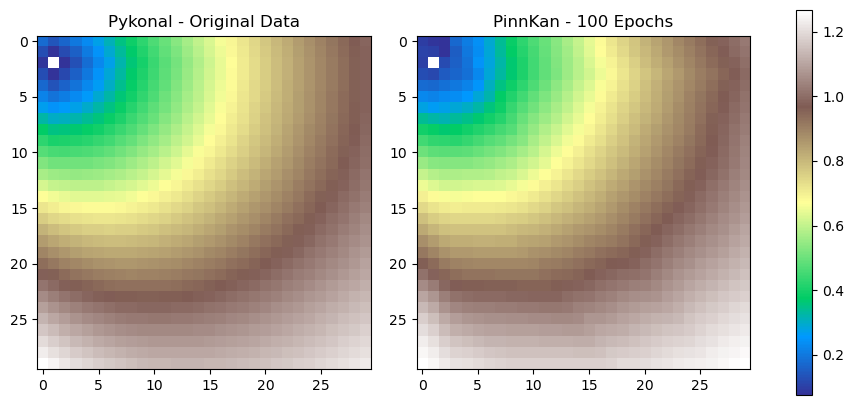

In [131]:
visualizando_resultados_on_training(100, 100)

/tmp/ipykernel_393906/4065197815.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


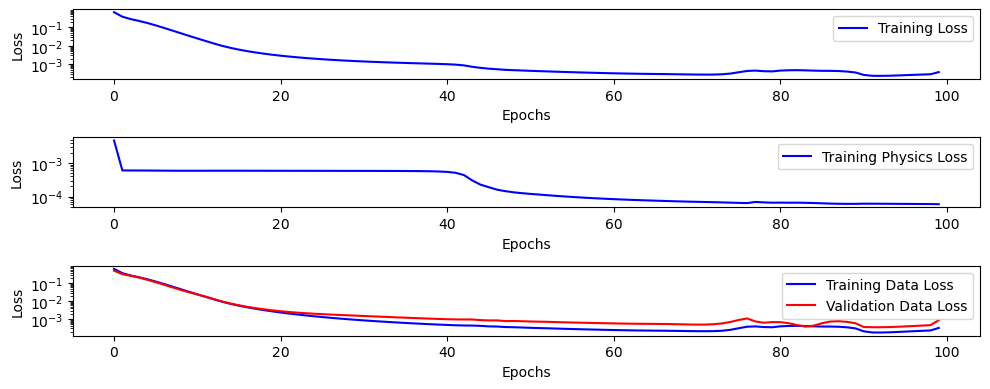

In [132]:
fig = arch.plot_losses()
fig.show()

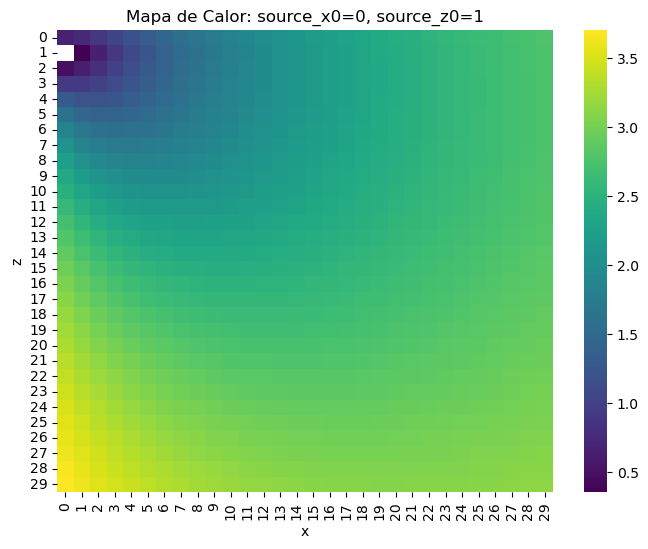

In [32]:
import seaborn as sns
def plot_heatmap_block(df, x_col, z_col, value_col, group_cols, block_index=0):
    """
    Plota um mapa de calor de um bloco específico do DataFrame agrupado.

    Parâmetros:
    - df: DataFrame do Pandas contendo os dados.
    - x_col: Nome da coluna para o eixo X.
    - z_col: Nome da coluna para o eixo Z.
    - value_col: Nome da coluna contendo os valores a serem plotados.
    - group_cols: Lista de colunas usadas para agrupar os blocos.
    - block_index: Índice do bloco a ser plotado (padrão: 0 - primeiro bloco).
    """
    # Agrupar os dados pelos pares especificados
    groups = list(df.groupby(group_cols))
    
    # Verificar se o índice está dentro do intervalo
    if block_index >= len(groups):
        print(f"Índice fora do intervalo. Escolha um número entre 0 e {len(groups) - 1}.")
        return
    
    # Obter o bloco solicitado
    (source_x0, source_z0), group = groups[block_index]
    
    # Plotar o mapa de calor
    plt.figure(figsize=(8, 6))
    pivot_table = group.pivot(index=z_col, columns=x_col, values=value_col)
    sns.heatmap(pivot_table, cmap='viridis')
    plt.title(f'Mapa de Calor: {group_cols[0]}={source_x0}, {group_cols[1]}={source_z0}')
    plt.show()

plot_heatmap_block(df, 'x', 'z', 'travel_time', ['source_x0', 'source_z0'], 1)

In [136]:
from utils.metrics import score

yhat = arch.predict(df_test[features].values)
score(yhat, df_test[target].values, labels=['Travel Time'])

,Travel Time
R²,0.991563
MAPE,0.035904
MAE,0.020898
MSE,0.000579
RMSE,0.024058


In [134]:
from typing import List, Optional


def plot_mse_heatmap_grid(
    dataset: pd.DataFrame,
    model,
    features: List[str],
    target: str,
    source: Optional[str] = None,
    ncols: int = 2,
    figsize: tuple = (12, 8)
):
    """
    Plota um mapa de calor do MSE para cada par (source_x0, source_z0),
    usando exatamente os pontos de grid definidos em 'x' e 'z', sem bins.

    Parâmetros:
    - dataset (pd.DataFrame): DataFrame com colunas 'x', 'z', 'source_x0', 'source_z0',
      além das colunas em 'features' e 'target'.
    - model: objeto com método predict(array) -> np.ndarray de predições.
    - features (List[str]): nomes das colunas de entrada para o modelo.
    - target (str): nome da coluna com valores verdadeiros.
    - source (Optional[str]): rótulo da fonte para o título dos gráficos.
    - ncols (int): número de colunas no grid de subplots.
    - figsize (tuple): tamanho da figura.
    """
    # Obter combinações únicas de source_x0 e source_z0
    sources = dataset[['source_x0', 'source_z0']].drop_duplicates().values
    nplots = len(sources)
    nrows = (nplots + ncols - 1) // ncols

    fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize)
    axs = np.array(axs).reshape(-1)  # achatar lista de eixos

    for ax, (sx, sz) in zip(axs, sources):
        # Filtrar apenas este par de source
        df_sub = dataset[(dataset['source_x0'] == sx) & (dataset['source_z0'] == sz)].copy()

        # Previsões e ground truth
        X = df_sub[features].values
        yhat = model.predict(X)
        y_true = df_sub[target].values

        # Erro ao quadrado
        df_sub['se'] = (yhat - y_true) ** 2

        # MSE por ponto (x, z)
        mse_df = df_sub.groupby(['x', 'z'], as_index=False)['se'].mean()
        pivot = mse_df.pivot(index='z', columns='x', values='se')
        pivot = pivot.sort_index(axis=0).sort_index(axis=1)

        x_vals = pivot.columns.values
        z_vals = pivot.index.values
        mse_grid = pivot.values

        # Desenhar heatmap com z invertido (0 no topo)
        im = ax.imshow(
            mse_grid,
            origin='upper',
            extent=[x_vals.min(), x_vals.max(), z_vals.max(), z_vals.min()],
            aspect='auto'
        )
        ax.set_xlabel('x')
        ax.set_ylabel('z')
        title = f'MSE ({sx}, {sz})'
        if source:
            title += f' - Fonte: {source}'
        ax.set_title(title)
        # Colorbar para cada subplot
        fig.colorbar(im, ax=ax, label='MSE')

    # Remover eixos extras
    for unused_ax in axs[nplots:]:
        unused_ax.axis('off')

    plt.tight_layout()
    plt.show()

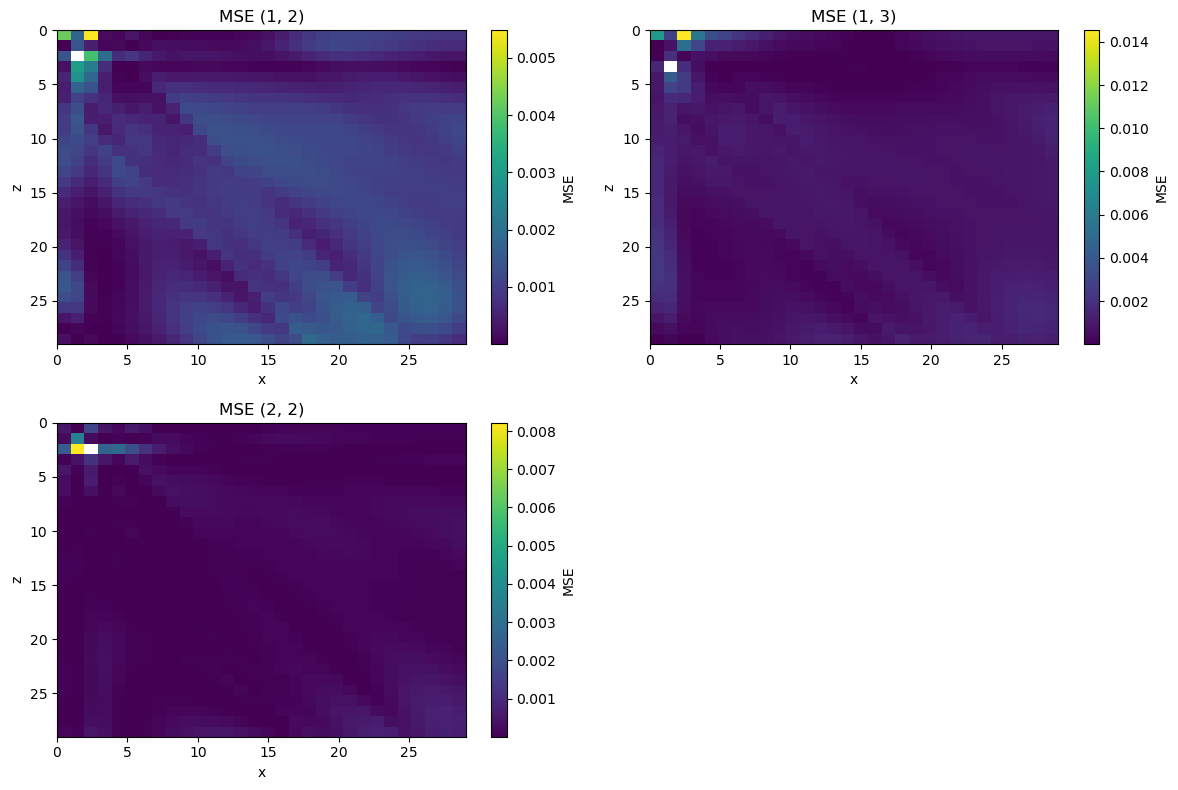

In [135]:
plot_mse_heatmap_grid(df_test, arch, features, target)

In [ ]:
# arch.save_checkpoint(f"output/checkpoint_{n_epochs}epochs.pt")